In [2]:
import mbddt as mb
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
#from get_model import get_model, plot_layout
import discretization
#import sys
#from os.path import join, expanduser
#home = expanduser("~")
#sys.path.append(join(home,'NextCloud/helpfullscripts/'))
#import import_all as ia

ModuleNotFoundError: No module named 'shapely'

In [3]:
nm = 1
deg = np.pi/180

keys = {
    'pitch': 100.,
    'height': 90,
    'height_offset_air': 20.,
    'height_offset_substrate': 10.,
    'height_etch_offset': 0,
    'thickness_oxid_Si_Si3N4': 1.24,
    'thickness_oxid': 4.1163659,
    'thickness_C': 0,
    'thickness_oxid_etch_offset': 3,
    'cd': 43.553261545145894,
    'swa': 85.886888403175917,
    'corner_r':5,
    'offset': 10,
    'R':5,
    'd_C': 0,
    'uol': 1,
    'uol1': 1,
    'mac_SiN_Nflou': 9694.99, #ehemals wa mass attenuation coefficient E_N=392.4eV
    'mac_SiO_Nflou': 8387.76,
    'mac_SiN_Oflou': 4234.66,  # ehemals wa mass attenuation coefficient E_O=524.9eV
    'mac_SiO_Oflou': 11108,
    'nk': [1 + 0 * 1j, 9.99126952e-01 + 2.58155424e-04*1j, 9.98750606e-01 + 2.58281215e-04*1j,
               9.99126952e-01 + 2.58155424e-04*1j,
               0.999007980921 + 0.000152309149j],
    'Si3N4dens': 2.835951527514214,  # /home/andrle01/Daten/2018/20180717_XRR_Si3N4/202001_Do_MCMC_all/
    'SiO2dens': 2.0929729034346574,
    'mac_SiO_Oflou': 11108,
    'w_N_SiN': 0.3994, #mass fraction
    'w_O_SiO': 0.45,
    'tau_N_K': 8668.79, # partial photoionization cross section of the N_K-shell
    'tau_O_K': 11356.9, # partial photoionization cross section of the O_K-shell
    'tau_C_K': 6138.54,
    'omega_N_K': 0.0045, #flourecence yielt
    'omega_O_K': 0.00688,
    'omega_C_K': 0.002575,
    'epsilon_N_K': 0.79492201, #detector efficiency
    'epsilon_O_K': 0.89835809,
    'epsilon_C_K': 0.64282511,
    'discretization' : 10, #higher means more boxes and more computation time
    'n_modes' : 15, #higher increases the comutation time
    'wl' : 1.82330 * nm,
    "AI" : np.linspace(0.01,3.0,50) * deg,
    "PHI" : np.linspace(0,+1.5,25) * deg
    }
#values of the BestFit used here for comparision
xx = {'height': 92.9935674631,
  'cd': 44.9326485504,
  'swa': 82.4841323908,
  'thickness_oxid': 2.4655511705,
  'height_etch_offset': 0,
  'thickness_oxid_etch_offset': 3.6665213398,
  'thickness_oxid_Si_Si3N4': 1.17,
  'aoi_offset': 0,
  'phi_offset': 0,
  'pitch': 100.8342460447}
keys.update(xx)

NameError: name 'np' is not defined

# Attenuation
$I_f = \exp(k'd)\int_{B} |E(z)|^2 \exp(-kz) dz$

$c_1 = \exp(k'd)$

$c_2 = k$



In [3]:
"""
This is attenuator function with global variable mu
Module will call it with an object of Beam,
so you can define how attenuation changes with respect to wavelength and geometry
"""

'\nThis is attenuator function with global variable mu\nModule will call it with an object of Beam,\nso you can define how attenuation changes with respect to wavelength and geometry\n'

In [4]:

class attr_o():
    """
    here the attenuator factor is calculated for given attenuation coefficient
    mu: attenuation coefficient of the layer we are looking at
    mu_O: attenuation coefficient of the oxygen layer
    mu_N: attenuation coefficient of the nitrogen layer
    coords: coordinates of all boxes of the strucutre
    x: coordintate of the layer we are looking at
    d: height of all layers
    i: index of the layer we are looking at
    beam: information about the beam
    attr: funtction that can calculate the factor for Kostyas code
    clac_c1: calculates the attenuation factor of all layers above the layer we are looking at
    """
    
    def __init__(self, mu, mu_O, mu_N, coords, x, d, i, c=1):
        self.c = c #*self.c1
        self.mu_N = (-mu_N)
        self.mu_O = (-mu_O)
        self.mu = mu
        self.all_c = 1
        self.coords = coords
        self.d = d
        self.x = x
        self.i_layer = i
        
    def attr(self,beam: mb.Beam):
        c1 = self.calc_c1(beam.alpha)*self.c
        return c1, (self.mu)/np.cos(beam.alpha)
    
    def calc_c1(self,alpha,test=False):
        mu_O = (self.mu_O/np.cos(alpha))
        mu_N = (self.mu_N/np.cos(alpha))
        #COORDS = self.coords
        x = self.x
        len_total = np.abs(x[1]-x[0])
        c = 1
        for ii in range(self.i_layer):
            delta = self.d[ii]
            coords = self.coords[ii]
            exp_mu_O = np.exp(mu_O*delta)
            exp_mu_N = np.exp(mu_N*delta)
            i0 = 5
            i1 = 5
            c1 = 0          
            #print(coords)
            if len(coords) == 2:
                mu_array = np.array([1,exp_mu_O,1])
                mu_text = np.array(['1','O','1'])
            elif len(coords) == 4:
                mu_array = np.array([1,exp_mu_O,exp_mu_N,exp_mu_O,1])
                mu_text = np.array(['1','O','N','O','1'])
                
            w_array = np.array([])
            for i in range(len(coords)):
                
                if x[0]<=coords[i] and i0 > i:
                    i0 = i
                    w_array = np.append(w_array,x[0])
                elif x[0]>coords[-1] and i == len(coords)-1:
                    i0 = i+1
                    i1 = i+1
                    w_array = np.append(w_array,x[0])
                    
                if x[1]<=coords[i] and i1 > i:
                    i1 = i
                elif x[1]>=coords[i] and x[0]<=coords[i]:
                    w_array = np.append(w_array,coords[i])
                    
            w_array = np.append(w_array,x[1])
            if i0 == i1:
               # mu_temp = (mu_array[i0])
                c1 = mu_array[i0]*np.abs(w_array[1]-w_array[0])
            else:
                mu_temp = (mu_array[i0:i1+1])
                for i,mu in enumerate(mu_temp):
                    c1 += mu*np.abs(w_array[i+1]-w_array[i])
            c *= c1/len_total
            if test:
                print('c: ',c)
                print('coords: ',coords)
                print('x: ',x)
                print(i0,i1)
                print('w_array: ',w_array)
                if i0 == i1:
                    print('mu: ',mu_text[i0])
                else:
                    print('mu: ',mu_text[i0:i1+1])
            #c1 = 1
        return c
    #return attr
i=2
#attr_o(2,3,0,COORDS,np.array([-20,0]),DELTA,2).calc_c1(0,test=True)

#DELTA, COORDS

In [5]:
#Initialize the layers
Si = mb.Material(color='black').set_chi(keys['nk'][-1]**2-1)
SiN = mb.Material(color='red', isfluorescent = True).set_chi(keys['nk'][2]**2-1)
SiO = mb.Material(color='green', isfluorescent = True).set_chi(keys['nk'][1]**2-1)
OO = mb.Material(color = "white").set_chi(0)

#Prepare the attenuation coefficents
#for the oxide layer
mu_SiO_Oflou = keys['mac_SiO_Oflou']*1e2*keys['SiO2dens']*1e-9
mu_SiO_Nflou = keys['mac_SiO_Nflou']*1e2*keys['SiO2dens']*1e-9
# for the nitride layer
mu_SiN_Oflou = keys['mac_SiN_Oflou']*1e2*keys['Si3N4dens']*1e-9
mu_SiN_Nflou = keys['mac_SiN_Nflou']*1e2*keys['Si3N4dens']*1e-9

pitch = keys['pitch']
n_modes = keys['n_modes']
offset =keys['height_offset_substrate']

sym = mb.Symmetry2D(pitch, n_modes)
sample = mb.Model(sym)
vacuum = mb.Layer(sym, offset).add_box(-pitch/2,pitch/2, OO)
"""
By default atteniator function is
c1 = 1, c2 = 0
"""
sample.add_layer(vacuum)

#get the discretization of the strucutre (uses the information of the keys)
DELTA, COORDS, OX, LI = discretization.get_discretization(keys) 

#itrates through all layers
for i, deltacoords in enumerate(zip(DELTA,COORDS)):
    delta = deltacoords[0]
    coords = deltacoords[1]
    layer = mb.Layer(sym, delta)
    if len(coords) == 4:
        layer.add_box(coords[0],coords[1], SiO, attenuator=attr_o(mu_SiO_Oflou,mu_SiO_Oflou,mu_SiN_Oflou,COORDS, coords[:2],DELTA,i).attr)        
        layer.add_box(coords[1],coords[2], SiN, attenuator=attr_o(mu_SiN_Nflou,mu_SiO_Nflou,mu_SiN_Nflou,COORDS, coords[1:3],DELTA,i).attr)
        layer.add_box(coords[2],coords[3], SiO, attenuator=attr_o(mu_SiO_Oflou,mu_SiO_Oflou,mu_SiN_Oflou,COORDS, coords[2:],DELTA,i).attr)
       
    elif len(coords) ==2:
        layer.add_box(coords[0],coords[1], SiO, attenuator=attr_o(mu_SiO_Oflou,mu_SiO_Oflou,mu_SiN_Oflou,COORDS, coords,DELTA,i).attr)
                
    sample.add_layer(layer)

substrate_oxide = mb.Layer(sym, keys['thickness_oxid_Si_Si3N4'])
substrate_oxide.add_box(-pitch/2,pitch/2, SiO, attenuator=attr_o(mu_SiO_Oflou,mu_SiO_Oflou,mu_SiN_Oflou,COORDS,np.array([-pitch/2,pitch/2]),DELTA,i+1).attr) 
substrate = mb.Layer(sym, offset).add_box(-pitch/2,pitch/2, Si)
sample.add_layer(substrate_oxide)
sample.add_layer(substrate)

In [6]:
#generates a sample without self attenuation
sample_o = mb.Model(sym)

vacuum = mb.Layer(sym, offset).add_box(-pitch/2,pitch/2, OO)
"""
By default atteniator function is
c1 = 1, c2 = 0
"""
sample_o.add_layer(vacuum)

DELTA, COORDS, OX, LI = discretization.get_discretization(keys) 
for i, deltacoords in enumerate(zip(DELTA,COORDS)):
    delta = deltacoords[0]
    coords = deltacoords[1]
    layer = mb.Layer(sym, delta)
    if len(coords) == 4:
        layer.add_box(coords[0],coords[1], SiO)        
        layer.add_box(coords[1],coords[2], SiN)
        layer.add_box(coords[2],coords[3], SiO)
    elif len(coords) ==2:
        layer.add_box(coords[0],coords[1], SiO)#, attenuator=attr_o(keys['mac_SiO_Oflou']*1e2*keys['SiO2dens'],0,w11, w12,w2,d).attr)
    sample_o.add_layer(layer)

substrate_oxide = mb.Layer(sym, keys['thickness_oxid_Si_Si3N4']).add_box(-pitch/2,pitch/2, SiO) #TODO hier fehlt attr
substrate = mb.Layer(sym, offset).add_box(-pitch/2,pitch/2, Si)
sample_o.add_layer(substrate_oxide)
sample_o.add_layer(substrate)

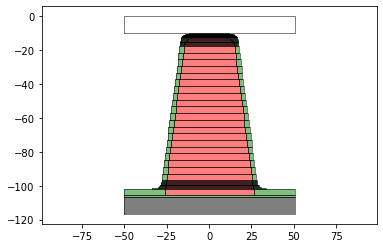

In [14]:
#look at the discrete structure
plt.close()
plt.figure()
ax = plt.gca()
sample.plot(ax)
plt.axis("equal")
plt.savefig("x.pdf")
plt.show()

In [9]:
#import the data calculated with JCM
data = np.load('20200417_BestFit.npy')
data = np.load('20200423_bestfit_s.npy')

plot_fit_jcm = {}
plot_fit_jcm['X'] = data[0, :]
plot_fit_jcm['exp'] = data[1, :]
plot_fit_jcm['exp1'] = data[2, :]
plot_fit_jcm['Y'] = data[3, :]
plot_fit_jcm['Y1'] = data[4, :]
plot_fit_jcm['Chi'] = np.square((data[1, :] - data[3, :])) / np.square(data[5, :])
plot_fit_jcm['Chi1'] = np.square((data[2, :] - data[4, :])) / np.square(data[5, :])
#plot_fit_jcm = ia.import_results(8)

In [10]:
#calculates the values with self attenuation
deg = np.pi/180
wl = 1.82330
AI = plot_fit_jcm['X'] # np.linspace(0.5,15,300)
PHI = 0
Y1 = np.zeros( (AI.size,) )
Y2 = np.zeros( (AI.size,) )
pbar = tqdm(total = Y1.size)
for i, ai in enumerate(AI):
    beam = mb.Beam(ai*deg,PHI*deg,wl)   
    #print(total_c)
    total_c = 1
    total_c_N=1
    total_c_O1=1
    total_c_O2=1
    #mu = mu1 = 5e-3
    Y = sample.calc_yield( beam )
    Y1[i] = Y[SiN]
    #mu = mu2 = 0
    Y2[i] = Y[SiO]
    pbar.update()
pbar.close()    
   

100%|██████████| 180/180 [12:54<00:00,  4.30s/it]


In [19]:
#calculates the values with  without self attenuation
Y1_o = np.zeros( (AI.size,) )
Y2_o = np.zeros( (AI.size,) )
pbar = tqdm(total = Y1_o.size)
for i, ai in enumerate(AI):
    beam = mb.Beam(ai*deg,PHI*deg,wl)    
    #mu = mu1 = 5e-3
    Y = sample_o.calc_yield( beam )
    Y1_o[i] = Y[SiN]
    #mu = mu2 = 0
    Y2_o[i] = Y[SiO]
    pbar.update()
pbar.close()  

100%|██████████| 180/180 [01:44<00:00,  1.72it/s]


In [ ]:
%reload_ext autoreload
%autoreload 2
#%matplotlib notebook
%matplotlib ipympl

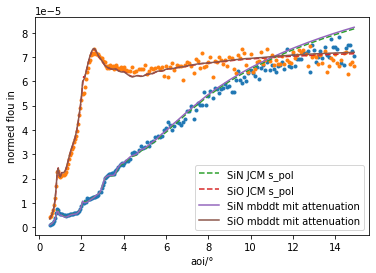

In [12]:
#plot the result
scale_N = 0.8532340707919255
scale_O = 1.1730265312446373
S_N = scale_N * 1e-7 * keys['tau_N_K'] * keys['omega_N_K'] * keys['w_N_SiN'] * keys['Si3N4dens'] / keys['pitch']
S_O = scale_O * 1e-7 * keys['tau_O_K'] * keys['omega_O_K'] * keys['w_O_SiO'] * keys['SiO2dens']  / keys['pitch']

plt.close()
#plt.plot(plot_fit_jcm['X'][0:183],plot_fit_jcm['exp'][0:183],'.')
#plt.plot(plot_fit_jcm['X'][0:183],plot_fit_jcm['exp1'][0:183],'.')
plt.plot(plot_fit_jcm['X'][0:],plot_fit_jcm['Y'][0:],'--',label = 'SiN JCM s_pol')
plt.plot(plot_fit_jcm['X'][0:],plot_fit_jcm['Y1'][0:],'--',label = 'SiO JCM s_pol')
#plt.plot(AI,Y1_o*S_N,'-.', label = 'SiN mbddt ohne attenuation' )
#plt.plot(AI,Y2_o*S_O,'-.', label = 'SiO mbddt ohne attenuation')
plt.plot(AI,Y1*S_N, label = 'SiN mbddt mit attenuation' )
plt.plot(AI,Y2*S_O, label = 'SiO mbddt mit attenuation')

#plt.xscale('log')
#plt.yscale('log')


#plt.xlim(0.5,6)
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
#plt.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.0e'))
plt.xlabel('aoi/°')
plt.ylabel('normed flou in')

plt.savefig("fig.pdf", dpi = 400)
plt.legend()
plt.show()

In [1]:
#plt.plot(plot_fit_jcm['X'][0:],plot_fit_jcm['Y'][0:],'--',label = 'SiN JCM')
#plt.plot(plot_fit_jcm['X'][0:],plot_fit_jcm['Y1'][0:],'--',label = 'SiO JCM')
plt.close()
plt.plot(AI,Y1_o*S_N/plot_fit_jcm['Y'][0:],'-.', label = 'SiN mbddt ohne attenuation' )
plt.plot(AI,Y2_o*S_O/plot_fit_jcm['Y1'][0:],'-.', label = 'SiO mbddt ohne attenuation')
plt.plot(AI,Y1*S_N/plot_fit_jcm['Y'][0:], label = 'SiN mbddt mit attenuation' )
plt.plot(AI,Y2*S_O/plot_fit_jcm['Y1'][0:], label = 'SiO mbddt mit attenuation')
plt.xlabel('aoi/°')

NameError: name 'plt' is not defined

In [70]:
Y1

array([  66.56464913,   73.14167916,   80.36925589,   88.35917245,
         97.25402786,  107.23770228,  118.54983298,  131.50573161,
        146.52331698,  164.15795014,  185.14273087,  210.42098091,
        241.12725682,  278.39761506,  322.73414367,  372.46249135,
        421.13698163,  456.03259756,  463.43346979,  440.8934665 ,
        400.98337016,  359.76131272,  326.63013261,  304.08778716,
        291.23193627,  286.23999333,  287.36417453,  293.13018561,
        302.20595319,  313.12128626,  301.41084481,  286.01992057,
        275.51855081,  266.90459283,  259.66246049,  253.66600171,
        248.88849032,  245.32832779,  242.9853891 ,  241.85248211,
        241.91165832,  243.13204977,  245.4682109 ,  248.8587774 ,
        253.22554571,  258.47315155,  264.48951212,  271.14715051,
        278.30546697,  285.81397121,  293.51644416,  301.25595589,
        308.88062439,  316.24995313,  323.24153399,  329.7578446 ,
        335.73281349,  341.13777988,  345.98644926,  350.33845

In [ ]:
deg = np.pi/180
wl = 2.4
AI = np.linspace(0.5,3,50)
PHI = np.linspace(-1.5,1.5,50)
Y1 = np.zeros( (AI.size,PHI.size) )
Y2 = np.zeros( (AI.size,PHI.size) )
pbar = tqdm(total = Y1.size)
for i, ai in enumerate(AI):
    for j, phi in enumerate(PHI):
        beam = mb.Beam(ai*deg, phi*deg, wl)    
        Y1[i,j] = sample.calc_yield( beam )[SiO2]
        Y2[i,j] = sample.calc_yield( beam )[Si]
        pbar.update()
pbar.close()
